In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
#from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, log_loss
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Input, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE

In [ ]:
#from google.colab import drive
#drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
clnf_df = pd.read_csv("complete_video_CLNF_woOutliers.csv")

In [ ]:
#clnf_df = shuffle(clnf_df).reset_index(drop = True)

In [4]:
display(clnf_df)

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x_h1,y_h1,z_h1,Tx,Ty,Tz,Rx,Ry,Rz,Target
0,555.284,558.627,564.580,572.835,587.197,609.909,636.677,667.409,701.499,735.698,...,-0.169596,0.411488,-0.895497,24.34710,47.5664,535.164,0.198389,0.055638,-0.117204,0
1,553.836,557.345,563.504,572.011,586.670,609.448,636.063,666.728,700.849,735.058,...,-0.156311,0.412949,-0.897240,24.00500,47.6058,534.351,0.202752,0.053431,-0.116840,0
2,532.799,536.637,543.247,552.044,566.449,588.831,615.234,645.604,679.725,714.324,...,-0.144607,0.401512,-0.904365,11.48700,47.4767,533.786,0.205838,0.078339,-0.136158,0
3,526.950,531.475,538.830,548.266,563.292,586.130,612.335,642.348,676.358,711.081,...,-0.143316,0.440597,-0.886191,8.98588,50.1869,533.380,0.236301,0.087538,-0.146588,0
4,528.201,532.602,539.979,549.496,564.572,587.422,613.444,643.165,677.078,711.875,...,-0.166556,0.422581,-0.890890,9.34586,50.1033,534.246,0.226615,0.091649,-0.148060,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
862963,688.813,687.697,688.834,692.796,702.436,719.107,738.604,760.416,789.233,820.469,...,-0.327926,0.119016,-0.937177,94.03810,66.5299,602.626,-0.015314,0.071895,0.070020,0
862964,691.019,690.003,691.233,694.980,704.084,720.123,738.788,760.644,789.861,821.521,...,-0.394559,0.139667,-0.908194,95.05850,69.5224,604.108,0.000672,0.081105,0.078013,0
862965,692.610,691.237,691.975,695.233,703.889,719.728,739.134,761.498,790.769,822.359,...,-0.366925,0.151943,-0.917758,95.97470,70.6911,602.907,0.017687,0.065976,0.082167,0
862966,694.402,692.673,693.218,696.296,704.583,720.073,739.882,762.459,792.029,824.016,...,-0.392165,0.153121,-0.907062,96.45800,70.9672,598.751,0.021469,0.069669,0.090121,0


In [5]:
clnf_df["Target"].value_counts()

Target
0    594425
1    268543
Name: count, dtype: int64

In [6]:
X = clnf_df.drop(columns=["Target"])
y = clnf_df["Target"]

In [7]:
# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# Reduce dimensionality using PCA
#pca = PCA(n_components=50)
#X_pca = pca.fit_transform(X_scaled)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

In [ ]:
class_weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

In [ ]:
# Apply SMOTE
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)


In [9]:
y_train.value_counts()

Target
0    475540
1    214834
Name: count, dtype: int64

# Evaluation functions

In [ ]:
# Evaluate Models
def evaluate_model(y_true, y_pred, model_name):
    print(f"Evaluation for {model_name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    print("Specificity:", specificity)
    print("ROC-AUC:", roc_auc_score(y_true, y_pred))

In [ ]:
# Plot Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix for {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [ ]:
# Plotting the training and validation accuracy and loss
def plot_training_history(history, model_name):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))
    #plt.rcParams.update({"font.size": 16})
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"Model Accuracy for {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["Training", "Validation"], loc="lower right")

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"Model Loss for {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["Training", "Validation"], loc="upper right")

    plt.tight_layout()
    plt.show()

In [ ]:
# Plot Precision-Recall Curve
def plot_roc_recall(model, X_test, y_test, model_name):
    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
    plt.plot(fpr, tpr, color="blue", lw=2, label="ROC curve")
    plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve for {model_name}")
    plt.legend(loc="lower right")
    plt.show()

    # Plot precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_test, model.predict(X_test))
    plt.plot(recall, precision, color="blue", lw=2, label="Precision-Recall curve")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve for {model_name}")
    plt.legend(loc="lower left")
    plt.show()

# RF

In [ ]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42,  verbose=2)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

building tree 1 of 100
building tree 2 of 100
building tree 3 of 100
building tree 4 of 100
building tree 5 of 100
building tree 6 of 100
building tree 7 of 100
building tree 8 of 100
building tree 9 of 100
building tree 10 of 100
building tree 11 of 100
building tree 12 of 100
building tree 13 of 100
building tree 14 of 100
building tree 15 of 100
building tree 16 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100
building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100
building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100
building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100
building tree 40 of 100


[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:  1.1min


building tree 41 of 100
building tree 42 of 100
building tree 43 of 100
building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67 of 100
building tree 68 of 100
building tree 69 of 100
building tree 70 of 100
building tree 71 of 100
building tree 72 of 100
building tree 73 of 100
building tree 74 of 100
building tree 75 of 100
building tree 76 of 100
building tree 77 of 100
building tree 78 of 100
building tree 79 of 100
building tree 80 of 100
building tree 81 of 100
building tree 82

[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.6s


In [ ]:
evaluate_model(y_test, rf_predictions, "Random Forest")

Evaluation for Random Forest
Confusion Matrix:
[[24478   440]
 [ 7701  3498]]
Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.98      0.86     24918
           1       0.89      0.31      0.46     11199

    accuracy                           0.77     36117
   macro avg       0.82      0.65      0.66     36117
weighted avg       0.80      0.77      0.73     36117

Accuracy: 0.7745936816457624
Precision: 0.888268156424581
Recall: 0.3123493169032949
F1 Score: 0.4621787672590342
Specificity: 0.9823420820290553
ROC-AUC: 0.647345699466175


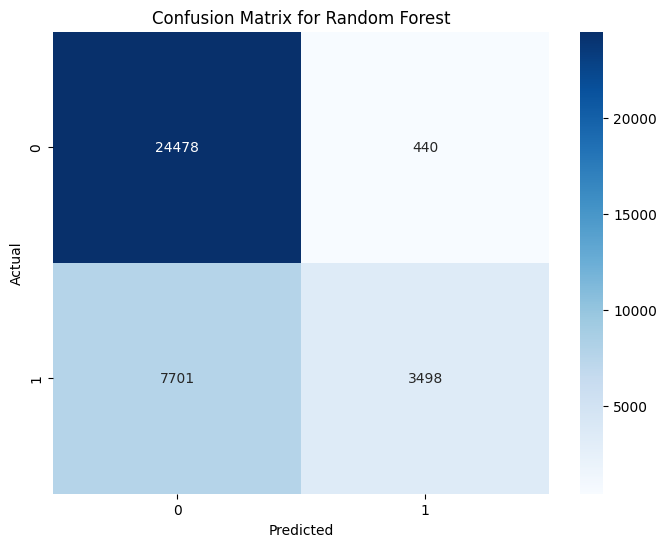

In [ ]:
plot_confusion_matrix(y_test, rf_predictions, "Random Forest")

# DT (not used)

In [ ]:
# Decision Tree
#dt_model = DecisionTreeClassifier(random_state=42)
#dt_model.fit(X_train, y_train)
#dt_predictions = dt_model.predict(X_test)

# GNB (not used)

In [ ]:
# Gaussian Naive Bayes
#gnb_model = GaussianNB()
#gnb_model.fit(X_train, y_train)
#gnb_predictions = gnb_model.predict(X_test)

# XGBoost (not used)

In [ ]:
# XGBoost
#xgb_model = XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)
#xgb_model.fit(X_train, y_train)
#xgb_predictions = xgb_model.predict(X_test)

# Extra Trees (not used)

In [ ]:
# Extra Trees
#et_model = ExtraTreesClassifier(n_estimators=100, random_state=42)
#et_model.fit(X_train, y_train)
#et_predictions = et_model.predict(X_test)

# LightGBM

In [ ]:
# LightGBM
lgbm_model = LGBMClassifier(random_state=42)
lgbm_model.fit(X_train, y_train)
lgbm_predictions = lgbm_model.predict(X_test)

[LightGBM] [Info] Number of positive: 99606, number of negative: 99606
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.167710 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 35689
[LightGBM] [Info] Number of data points in the train set: 199212, number of used features: 140
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


In [ ]:
evaluate_model(y_test, lgbm_predictions, "LightGBM")

Evaluation for LightGBM
Confusion Matrix:
[[23575  1327]
 [ 8810  2405]]
Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.95      0.82     24902
           1       0.64      0.21      0.32     11215

    accuracy                           0.72     36117
   macro avg       0.69      0.58      0.57     36117
weighted avg       0.70      0.72      0.67     36117

Accuracy: 0.7193288479109561
Precision: 0.6444265809217578
Recall: 0.21444493981275078
F1 Score: 0.32180370642938383
Specificity: 0.946711107541563
ROC-AUC: 0.5805780236771569


In [ ]:
plot_confusion_matrix(y_test, lgbm_predictions, "LightGBM")

In [ ]:
plot_roc_recall(lgbm_model, X_test, y_test, "LightGBM")

# CNN (not used)

In [ ]:
#X_train = X_train.to_numpy()

In [ ]:
# CNN
#cnn_model = models.Sequential()
#cnn_model.add(layers.Conv1D(64, 2, activation="relu", input_shape=(X_train.shape[1], 1)))
#cnn_model.add(layers.MaxPooling1D(2))
#cnn_model.add(layers.Conv1D(128, 2, activation="relu"))
#cnn_model.add(layers.GlobalMaxPooling1D())
#cnn_model.add(layers.Dense(64, activation="relu"))
#cnn_model.add(layers.Dropout(0.5))
#cnn_model.add(layers.Dense(1, activation="sigmoid"))

#cnn_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
#cnn_history = cnn_model.fit(X_train.reshape(-1, X_train.shape[1], 1), y_train, epochs=10, batch_size=32, validation_split=0.2)
#cnn_predictions = cnn_model.predict(X_test.reshape(-1, X_test.shape[1], 1)).round().astype(int)

In [ ]:
#evaluate_model(y_test, cnn_predictions, "CNN")

In [ ]:
#plot_confusion_matrix(y_test, cnn_predictions, "CNN")

In [ ]:
#plot_training_history(cnn_history, "CNN")

In [ ]:
#plot_roc_recall(bilstm_model, X_test, y_test, "CNN")

# BiLSTM ((not used))

In [ ]:
# BiLSTM
#bilstm_model = models.Sequential()
#bilstm_model.add(Bidirectional(LSTM(64, return_sequences=True), input_shape=(X_train.shape[1], 1)))
#bilstm_model.add(LSTM(32))
#bilstm_model.add(Dense(1, activation="sigmoid"))

#bilstm_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
#bilstm_history = bilstm_model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)
#bilstm_predictions = bilstm_model.predict(X_test, 1).round().astype(int)

In [ ]:
#evaluate_model(y_test, bilstm_predictions, "BiLSTM")

In [ ]:
#plot_confusion_matrix(y_test, bilstm_predictions, "BiLSTM")

In [ ]:
#plot_training_history(bilstm_history, "BiLSTM")

In [ ]:
#plot_roc_recall(bilstm_model, X_test, y_test, "BiLSTM")

# FFNN

In [11]:
# FFNN
input_shape = X_train.shape[1]
ffnn_model = models.Sequential()
ffnn_model.add(Input(shape=(input_shape,)))
ffnn_model.add(Dense(256, activation="relu"))
ffnn_model.add(Dropout(0.3))
ffnn_model.add(Dense(128, activation="relu"))
ffnn_model.add(Dropout(0.3))
ffnn_model.add(Dense(64, activation="relu"))
ffnn_model.add(Dropout(0.5))
ffnn_model.add(Dense(32, activation="relu"))
ffnn_model.add(Dropout(0.5))
ffnn_model.add(Dense(8, activation="relu"))
ffnn_model.add(Dense(1, activation="sigmoid"))

ffnn_model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
ffnn_history = ffnn_model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)
ffnn_predictions = (ffnn_model.predict(X_test) > 0.5).astype(int)

Epoch 1/10
17260/17260 ━━━━━━━━━━━━━━━━━━━━ 120s 7ms/step - accuracy: 0.6789 - loss: 1.9689 - val_accuracy: 0.6907 - val_loss: 0.6186
Epoch 2/10
17260/17260 ━━━━━━━━━━━━━━━━━━━━ 118s 7ms/step - accuracy: 0.6889 - loss: 0.6200 - val_accuracy: 0.6907 - val_loss: 0.6186
Epoch 3/10
17260/17260 ━━━━━━━━━━━━━━━━━━━━ 118s 7ms/step - accuracy: 0.6871 - loss: 0.6214 - val_accuracy: 0.6907 - val_loss: 0.6186
Epoch 4/10
 9954/17260 ━━━━━━━━━━━━━━━━━━━━ 44s 6ms/step - accuracy: 0.6897 - loss: 0.6193

KeyboardInterrupt: 

In [ ]:
evaluate_model(y_test, ffnn_predictions, "FFNN")

In [ ]:
evaluate_model(y_test, ffnn_predictions, "FFNN")

Evaluation for FFNN
Confusion Matrix:
[[21366  3536]
 [ 4412  6803]]
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84     24902
           1       0.66      0.61      0.63     11215

    accuracy                           0.78     36117
   macro avg       0.74      0.73      0.74     36117
weighted avg       0.78      0.78      0.78     36117

Accuracy: 0.7799374255890578
Precision: 0.6579940032885192
Recall: 0.6065983058403923
F1 Score: 0.6312517398162755
Specificity: 0.8580033732230343
ROC-AUC: 0.7323008395317133


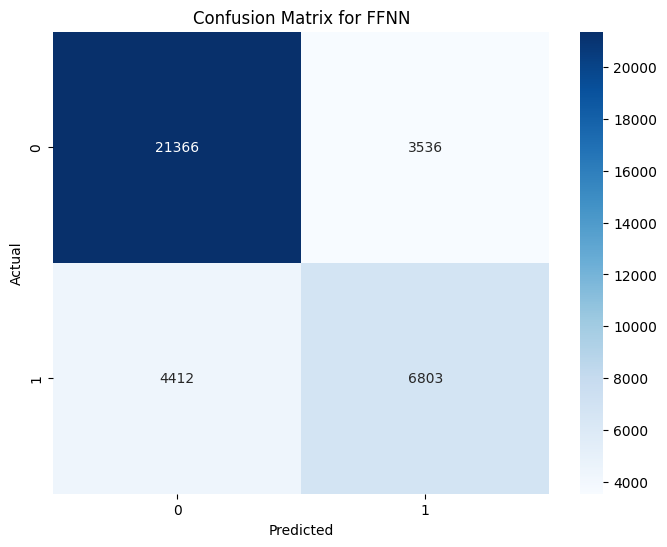

In [ ]:
plot_confusion_matrix(y_test, ffnn_predictions, "FFNN")

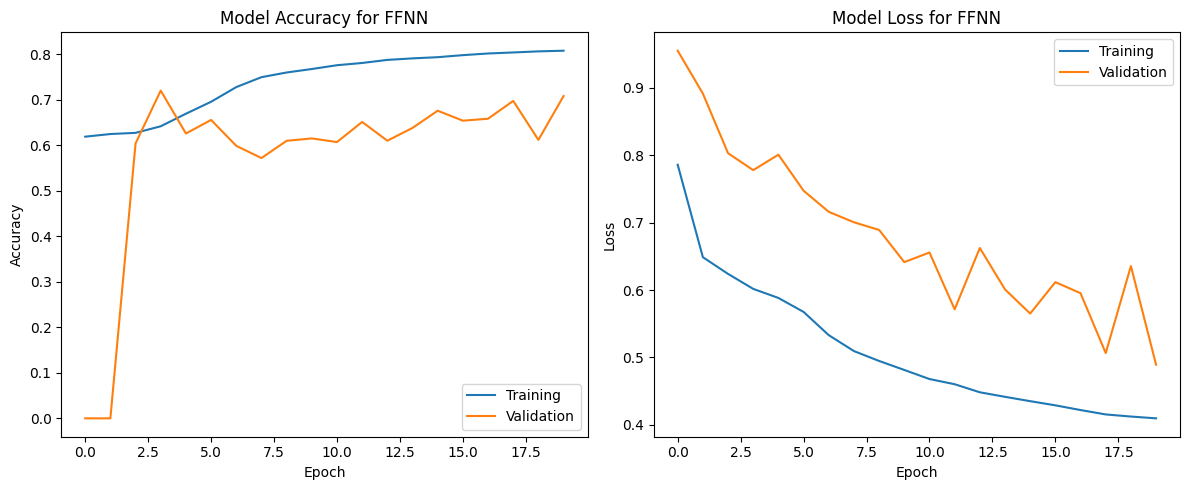

In [ ]:
plot_training_history(ffnn_history, "FFNN")

1129/1129 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


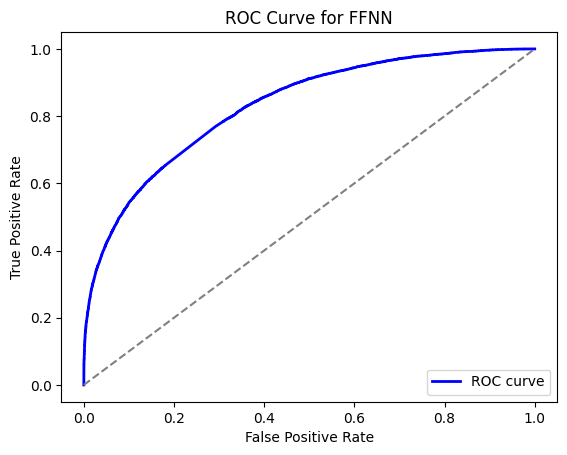

1129/1129 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


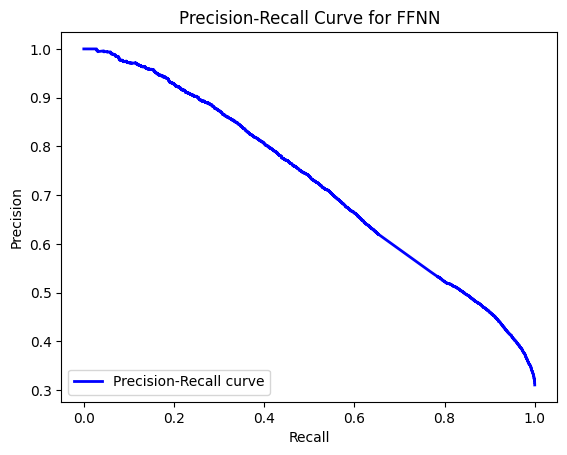

In [ ]:
plot_roc_recall(ffnn_model, X_test, y_test, "FFNN")